In [1]:
print("Hello world")

Hello world


In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [10]:
np.arange(6, 67)

array([ 6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22,
       23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39,
       40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56,
       57, 58, 59, 60, 61, 62, 63, 64, 65, 66])

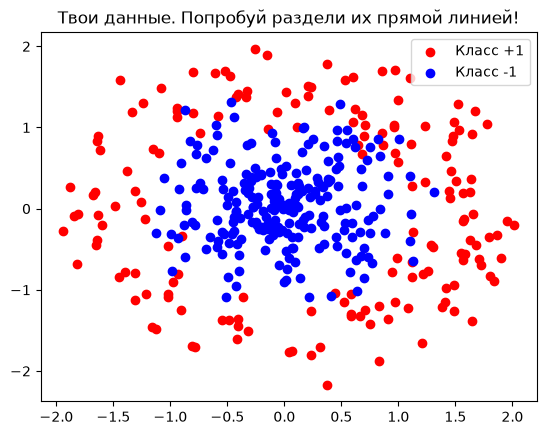

In [11]:
# Я сам генерирую тебе данные. Никакой халявы.
np.random.seed(42)
n_samples = 400

# Генерируем "бублик" (два концентрических класса)
r = np.random.uniform(0, 2, n_samples)
theta = np.random.uniform(0, 2 * np.pi, n_samples)
X = np.c_[r * np.cos(theta), r * np.sin(theta)]

# Класс +1 для внешнего кольца, -1 для внутреннего
y = np.where(r > 1.2, 1, -1)

# Добавляем гауссовский шум, чтобы жизнь медом не казалась
X += np.random.normal(0, 0.15, X.shape)

# Посмотри, с чем имеешь дело
plt.scatter(X[y==1, 0], X[y==1, 1], color='red', label='Класс +1')
plt.scatter(X[y==-1, 0], X[y==-1, 1], color='blue', label='Класс -1')
plt.legend()
plt.title("Твои данные. Попробуй раздели их прямой линией!")
plt.show()

In [34]:
X

array([[ 4.78689190e-01,  5.22827837e-01],
       [ 1.83832032e+00, -8.91001237e-01],
       [-1.22421274e+00, -1.24987568e-01],
       [ 4.04876288e-01, -1.08066284e+00],
       [-1.24588261e-01,  4.46427081e-01],
       [-6.72267884e-03,  3.90237399e-02],
       [-1.12837021e-01,  1.04636558e-02],
       [ 1.57652179e+00, -1.30355163e-01],
       [ 1.11943565e+00, -6.62367426e-01],
       [ 9.96023226e-01,  5.74188280e-01],
       [-6.77357995e-02,  2.87679291e-01],
       [ 1.80617272e+00, -8.24190348e-01],
       [ 1.54848965e+00, -5.49342271e-01],
       [-7.84798144e-01, -1.97220958e-01],
       [-2.80499101e-01, -1.63514311e-01],
       [-7.03889723e-02,  2.85736818e-01],
       [-2.03515475e-01,  4.20216430e-01],
       [-1.11867921e-01,  9.32787971e-01],
       [-4.02061973e-01, -7.67141958e-01],
       [ 3.84024412e-02, -6.04047517e-01],
       [ 2.30018258e-01, -1.26421206e+00],
       [ 6.38198953e-02, -3.51902212e-01],
       [ 3.84018203e-01,  3.32771921e-01],
       [-7.

In [47]:
def expand_features(matrix):
    new_matrix = np.append(matrix, (matrix[:,[0]] ** 2), axis=1)
    new_matrix = np.append(new_matrix, (matrix[:,[1]] ** 2), axis=1)
    new_matrix = np.append(new_matrix, (np.ones((400, 1))), axis=1)
    return new_matrix
new_matrix = expand_features(X)

In [49]:
w = np.linalg.inv(new_matrix.T @ new_matrix) @ (new_matrix.T * y)
w

array([[-0.00181628,  0.00459589, -0.00530273, ...,  0.00359593,
        -0.00208878,  0.00425482],
       [-0.00193469, -0.00300386, -0.00049434, ...,  0.00092764,
        -0.00602923, -0.00211604],
       [ 0.00166207,  0.00685182,  0.00317335, ..., -0.00073859,
        -0.00130842,  0.00418638],
       [ 0.00147625,  0.00075603, -0.0020306 , ...,  0.0020116 ,
         0.00491321, -0.00077938],
       [-0.00438144, -0.0031985 ,  0.00202683, ..., -0.00361392,
         0.00074845, -0.00032126]], shape=(5, 400))

In [ ]:
def predict(new_matrix, w):
    return np.sign(